<a href="https://colab.research.google.com/github/Shritej1104/pytorch-learning/blob/main/simple_neuralnetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [3]:
# create a model class that inherits nn.Module
class Model(nn.Module):
  # input layer (4 features)--> hidden layer-->h2-->output(classes of iris flower)
  def __init__(self, in_features=4, h1=8, h2=9, out_features=3):
    super().__init__()
    self.fc1 = nn.Linear(in_features, h1)
    self.fc2 = nn.Linear(h1, h2)
    self.out = nn.Linear(h2, out_features)

  def forward(self, x):
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = self.out(x)
    return x

In [4]:
# pick manual seed for randomization
torch.manual_seed(41)
# create an instance of model
model = Model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [5]:
# above we created a model
# not lets load the dataset and train the modell\

In [7]:
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd


In [8]:
url='https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv'
my_df=pd.read_csv(url)

In [11]:
my_df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [10]:
# lets get rid og words in last row and make in numbers (converting strings to integers)
my_df['species']= my_df['species'].replace('setosa', 0)
my_df['species']= my_df['species'].replace('versicolor', 1)
my_df['species']= my_df['species'].replace('virginica', 2)
#

/tmp/ipykernel_2207/1131604178.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  my_df['species']= my_df['species'].replace('virginica', 2)


In [16]:
# lets train test spilt srt X, Y
X  = my_df.drop('species', axis=1)
Y= my_df['species']
# convert all into numpy arrays
X=X.values
Y=Y.values


In [17]:
from sklearn.model_selection import train_test_split
# Train test split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=41)

In [18]:
# Convert x features to float tensors
X_train= torch.FloatTensor(X_train)
X_test= torch.FloatTensor(X_test)
# convert Y labes to long tensors
Y_train= torch.LongTensor(Y_train)
Y_test= torch.LongTensor(Y_test)
#

In [19]:
# set criteria to measure the errior , how far the prediction are from data
criterion= nn.CrossEntropyLoss()
# set optimizer  lr = lernnng rate (if error doent go down after some iterations we should lower lr)
optimizer= torch.optim.Adam(model.parameters(), lr=0.01)

In [22]:
# if we wnt to see the layers
model.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)>

In [29]:
# train model
# Epoch (one run thru all the training data in our network)
epochs = 100
losses = []
for i in range(epochs):
  y_pred = model(X_train) # get predicted results
  # measure loss/error
  loss = criterion(y_pred, Y_train)

  # keep track of our losses
  losses.append(loss.detach().numpy())

  if i % 10 == 0:
    print(f'Epoch:{i} and losses:{loss.item()}')

  # back propagation
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

NotImplementedError: Module [Model] is missing the required "forward" function

In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Create a model class that inherits nn.Module
class Model(nn.Module):
    # Input layer (4 features) --> Hidden layer 1 (8) --> Hidden layer 2 (9) --> Output (3 classes)
    def __init__(self, in_features=4, h1=8, h2=9, out_features=3):
        super().__init__()
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)

    # Indented properly inside the Model class:
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)
        return x

# Re-initialize the model with the corrected class
torch.manual_seed(41)
model = Model()

# Re-initialize optimizer with the new model's parameters
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [35]:
# Train the model
epochs = 200
losses = []

for i in range(epochs):
    # Forward pass
    y_pred = model(X_train)

    # Measure loss
    loss = criterion(y_pred, Y_train)
    losses.append(loss.detach().numpy())

    if i % 10 == 0:
        print(f'Epoch: {i:2d} | Loss: {loss.item():.4f}')

    # Backpropagation and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

Epoch:  0 | Loss: 0.0168
Epoch: 10 | Loss: 0.0155
Epoch: 20 | Loss: 0.0145
Epoch: 30 | Loss: 0.0134
Epoch: 40 | Loss: 0.0127
Epoch: 50 | Loss: 0.0119
Epoch: 60 | Loss: 0.0113
Epoch: 70 | Loss: 0.0109
Epoch: 80 | Loss: 0.0101
Epoch: 90 | Loss: 0.0095
Epoch: 100 | Loss: 0.0090
Epoch: 110 | Loss: 0.0086
Epoch: 120 | Loss: 0.0087
Epoch: 130 | Loss: 0.0079
Epoch: 140 | Loss: 0.0074
Epoch: 150 | Loss: 0.0071
Epoch: 160 | Loss: 0.0067
Epoch: 170 | Loss: 0.0065
Epoch: 180 | Loss: 0.0062
Epoch: 190 | Loss: 0.0059


Text(0.5, 0, 'Epoch')

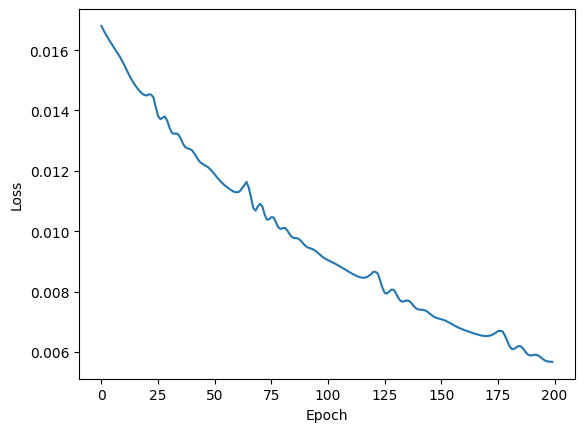

In [36]:
# graph
plt.plot(range(epochs),losses)
plt.ylabel('Loss')
plt.xlabel('Epoch')